# Steam Games Dataset - Exploratory Data Analysis (EDA)

## Project Objective

The objective of this exploratory data analysis is to understand the structure, quality, pricing patterns, review behavior, and business characteristics of the Steam Games dataset before performing data cleaning, transformation, SQL analysis, statistical testing, and dashboard development.

1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

pd.set_option("display.max_columns", None)

2. Load Dataset

In [2]:
df = pd.read_csv("../data/raw/game.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 71700
Columns: 16


,Title,Original Price,Discounted Price,Release Date,Link,Game Description,Recent Reviews Summary,All Reviews Summary,Recent Reviews Number,All Reviews Number,Developer,Publisher,Supported Languages,Popular Tags,Game Features,Minimum Requirements
0,Baldur's Gate 3,$29.99,$29.99,"3 Aug, 2023",https://store.steampowered.com/app/1086940/Bal...,"Baldur’s Gate 3 is a story-rich, party-based R...",Overwhelmingly Positive,Very Positive,"- 96% of the 128,900 user reviews in the last ...","- 94% of the 188,617 user reviews for this gam...",Larian Studios,Larian Studios,"['English', 'French', 'German', 'Spanish - Spa...","['RPG', 'Choices Matter', 'Character Customiza...","['Single-player', 'Online Co-op', 'LAN Co-op',...",Requires a 64-bit processor and operating syst...
1,Counter-Strike: Global Offensive,$14.99,$14.99,"21 Aug, 2012",https://store.steampowered.com/app/730/Counter...,Counter-Strike: Global Offensive (CS: GO) expa...,Very Positive,Very Positive,"- 89% of the 75,284 user reviews in the last 3...","- 88% of the 7,428,921 user reviews for this g...","Valve, Hidden Path Entertainment",Valve,"['English', 'Czech', 'Danish', 'Dutch', 'Finni...","['FPS', 'Shooter', 'Multiplayer', 'Competitive...","['Steam Achievements', 'Full controller suppor...",OS: | Windows® 7/Vista/XP | Processor: | Int...
2,Apex Legends™,Free,Free,"4 Nov, 2020",https://store.steampowered.com/app/1172470/Ape...,"Apex Legends is the award-winning, free-to-pla...",Mixed,Very Positive,"- 65% of the 18,581 user reviews in the last 3...","- 80% of the 701,597 user reviews for this gam...",Respawn Entertainment,Electronic Arts,"['English', 'French', 'Italian', 'German', 'Sp...","['Free to Play', 'Multiplayer', 'Battle Royale...","['Online PvP', 'Online Co-op', 'Steam Achievem...",Requires a 64-bit processor and operating syst...
3,Forza Horizon 5,$34.78,$17.39,"8 Nov, 2021",https://store.steampowered.com/app/1551360/For...,Your Ultimate Horizon Adventure awaits! Explor...,Very Positive,Very Positive,"- 87% of the 4,120 user reviews in the last 30...","- 88% of the 123,162 user reviews for this gam...",Playground Games,Xbox Game Studios,"['English', 'French', 'Italian', 'German', 'Sp...","['Racing', 'Open World', 'Driving', 'Multiplay...","['Single-player', 'Online PvP', 'Online Co-op'...",Requires a 64-bit processor and operating syst...
4,Call of Duty®,Free,Free,"27 Oct, 2022",https://store.steampowered.com/app/1938090/Cal...,"Welcome to Call of Duty® HQ, the home of Call ...",Mixed,Mixed,"- 49% of the 8,257 user reviews in the last 30...","- 57% of the 236,876 user reviews for this gam...","Infinity Ward, Raven Software, Beenox, Treyarc...",Activision,"['English', 'French', 'Italian', 'German', 'Sp...","['FPS', 'Multiplayer', 'Shooter', 'Action', 'S...","['Single-player', 'Online PvP', 'Online Co-op'...",Requires a 64-bit processor and operating syst...


3. Dataset Overview

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 71700 entries, 0 to 71699
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Title                   71699 non-null  str  
 1   Original Price          71700 non-null  str  
 2   Discounted Price        71700 non-null  str  
 3   Release Date            71569 non-null  str  
 4   Link                    71700 non-null  str  
 5   Game Description        71489 non-null  str  
 6   Recent Reviews Summary  56480 non-null  str  
 7   All Reviews Summary     5371 non-null   str  
 8   Recent Reviews Number   56480 non-null  str  
 9   All Reviews Number      5371 non-null   str  
 10  Developer               71479 non-null  str  
 11  Publisher               71183 non-null  str  
 12  Supported Languages     71700 non-null  str  
 13  Popular Tags            71700 non-null  str  
 14  Game Features           71700 non-null  str  
 15  Minimum Requirements    70576 

In [4]:
df.describe(include="all")

,Title,Original Price,Discounted Price,Release Date,Link,Game Description,Recent Reviews Summary,All Reviews Summary,Recent Reviews Number,All Reviews Number,Developer,Publisher,Supported Languages,Popular Tags,Game Features,Minimum Requirements
count,71699,71700,71700,71569,71700,71489,56480,5371,56480,5371,71479,71183,71700,71700,71700,70576
unique,71699,654,827,4441,71700,71090,18,7,13391,5296,45353,38543,11058,65817,5418,63201
top,Baldur's Gate 3,Free,Free,Coming soon,https://store.steampowered.com/app/1086940/Bal...,Find the objects that are hidden on the map.,Very Positive,Very Positive,- Need more user reviews to generate a score,- 90% of the 624 user reviews for this game ar...,Choice of Games,Big Fish Games,['English'],"['Indie', 'Casual']",['Single-player'],Requires a 64-bit processor and operating syst...
freq,1,17585,17585,5887,1,34,11039,3151,18999,3,162,459,38083,284,17262,274


In [5]:
df.nunique()

Title                     71699
Original Price              654
Discounted Price            827
Release Date               4441
Link                      71700
Game Description          71090
Recent Reviews Summary       18
All Reviews Summary           7
Recent Reviews Number     13391
All Reviews Number         5296
Developer                 45353
Publisher                 38543
Supported Languages       11058
Popular Tags              65817
Game Features              5418
Minimum Requirements      63201
dtype: int64

In [6]:
df.columns.tolist()

['Title',
 'Original Price',
 'Discounted Price',
 'Release Date',
 'Link',
 'Game Description',
 'Recent Reviews Summary',
 'All Reviews Summary',
 'Recent Reviews Number',
 'All Reviews Number',
 'Developer',
 'Publisher',
 'Supported Languages',
 'Popular Tags',
 'Game Features',
 'Minimum Requirements']

4. Missing Values Analysis

In [7]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": round(df.isnull().mean()*100,2)
})

missing.sort_values(
    by="Missing %",
    ascending=False
)

,Missing Count,Missing %
All Reviews Summary,66329,92.51
All Reviews Number,66329,92.51
Recent Reviews Number,15220,21.23
Recent Reviews Summary,15220,21.23
Minimum Requirements,1124,1.57
Publisher,517,0.72
Developer,221,0.31
Game Description,211,0.29
Release Date,131,0.18
Title,1,0.00


5. Duplicate Check

In [8]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


6. Price Cleaning

In [9]:
def clean_price(price):

    if pd.isna(price):
        return np.nan

    price = str(price).strip()

    if price.lower() == "free":
        return 0

    price = price.replace("$","")
    price = price.replace(",","")

    try:
        return float(price)

    except:
        return np.nan

In [10]:
df["original_price"] = (
    df["Original Price"]
    .apply(clean_price)
)

df["discounted_price"] = (
    df["Discounted Price"]
    .apply(clean_price)
)

7. Price Analysis

In [11]:
df["original_price"].describe()

count    7.170000e+04
mean     5.943817e+02
std      9.085764e+04
min      0.000000e+00
25%      7.900000e-01
50%      2.790000e+00
75%      6.290000e+00
max      1.404633e+07
Name: original_price, dtype: float64

In [12]:
df["discounted_price"].describe()

count    7.170000e+04
mean     1.821652e+02
std      2.725962e+04
min      0.000000e+00
25%      3.400000e-01
50%      2.690000e+00
75%      6.290000e+00
max      4.213900e+06
Name: discounted_price, dtype: float64

In [13]:
df["original_price"].quantile(
    [0.90,0.95,0.99,0.995,0.999]
)

0.900     10.4900
0.950     12.5900
0.990     29.9900
0.995     45.9900
0.999    277.3547
Name: original_price, dtype: float64

In [14]:
df["discounted_price"].quantile(
    [0.90,0.95,0.99,0.995,0.999]
)

0.900     9.99000
0.950    12.49000
0.990    24.99000
0.995    34.12635
0.999    59.99000
Name: discounted_price, dtype: float64

8. Outlier Investigation

In [15]:
df[
    ["Title","original_price"]
].sort_values(
    by="original_price",
    ascending=False
).head(50)

,Title,original_price
52064,Jack-O-Lantern Covers of Darkness,14046333.00
60721,Fright,14046333.00
52065,Roller,14046333.00
39897,Nomad Station,100000.00
63158,Orpiment,9999.00
13889,BLACKOUT,1999.98
47398,Beach Volleyball Competition,1234.57
38641,Snowboard,1189.77
44038,Hidden Water,1101.77
36878,Hidden Town,1101.77


In [16]:
df[
    df["original_price"] > 500
][
    ["Title","original_price"]
].sort_values(
    by="original_price",
    ascending=False
)

,Title,original_price
52064,Jack-O-Lantern Covers of Darkness,14046333.00
52065,Roller,14046333.00
60721,Fright,14046333.00
39897,Nomad Station,100000.00
63158,Orpiment,9999.00
13889,BLACKOUT,1999.98
47398,Beach Volleyball Competition,1234.57
38641,Snowboard,1189.77
31968,Hidden Islands,1101.77
36878,Hidden Town,1101.77


In [17]:
df[
    ["Title","discounted_price"]
].sort_values(
    by="discounted_price",
    ascending=False
).head(30)

,Title,discounted_price
52064,Jack-O-Lantern Covers of Darkness,4213899.90
52065,Roller,4213899.90
60721,Fright,4213899.90
39897,Nomad Station,100000.00
63158,Orpiment,9999.00
13889,BLACKOUT,1999.98
47398,Beach Volleyball Competition,1234.57
36602,Blue Epic,1000.00
36204,Ascent Free-Roaming VR Experience,999.00
36136,The Hidden and Unknown,890.99


9. Price Distribution

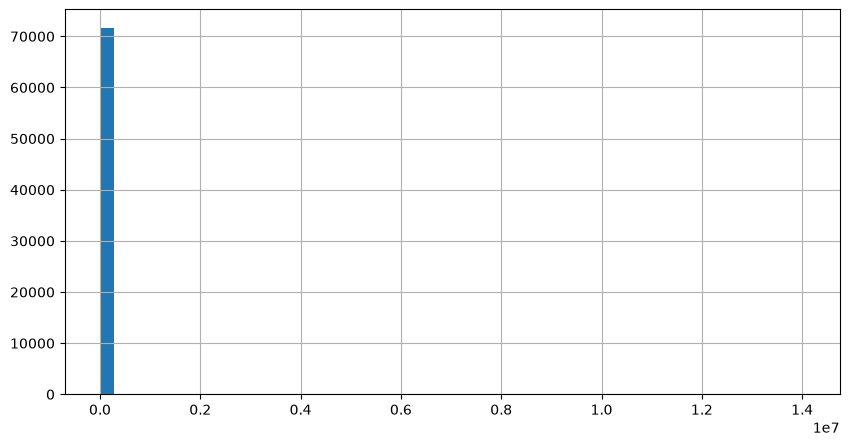

In [18]:
plt.figure(figsize=(10,5))

df["original_price"].hist(
    bins=50
)

plt.show()

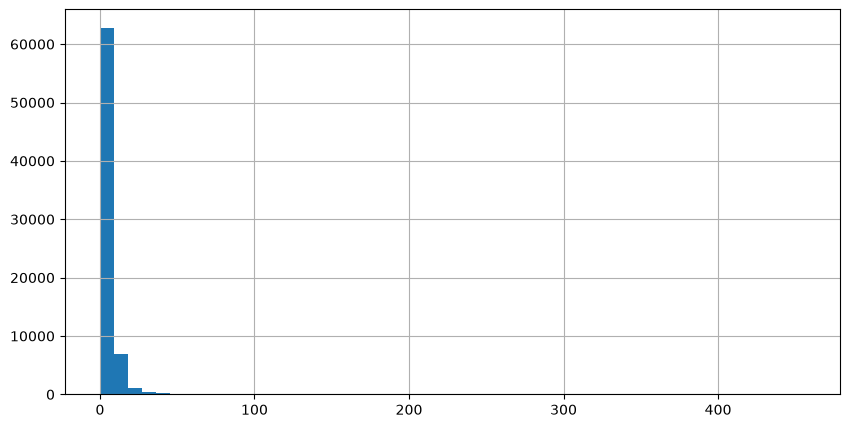

In [19]:
df_filtered = df[
    df["original_price"] <= 500
]

plt.figure(figsize=(10,5))

df_filtered["original_price"].hist(
    bins=50
)

plt.show()

10. Release Date Analysis

In [20]:
df["Release Date"].value_counts().head(20)

Release Date
Coming soon        5887
To be announced    1809
2023                787
Q4 2023             392
2024                388
Q3 2023             138
Q1 2024             118
14 Jul, 2023         83
October 2023         78
17 Jan, 2020         76
30 Mar, 2023         75
16 Dec, 2022         70
20 Jul, 2023         69
25 May, 2023         69
31 Mar, 2023         69
20 Jan, 2023         69
September 2023       69
30 Sep, 2022         67
1 Dec, 2022          66
1 Jun, 2023          65
Name: count, dtype: int64

In [21]:
df["release_date"] = pd.to_datetime(
    df["Release Date"],
    errors="coerce"
)

df["release_year"] = (
    df["release_date"]
    .dt.year
)

In [22]:
df["release_year"].describe()

count    61394.000000
mean      2019.563606
std         22.435048
min       1969.000000
25%       2018.000000
50%       2020.000000
75%       2022.000000
max       6969.000000
Name: release_year, dtype: float64

In [23]:
df["release_year"].value_counts().head(30)

release_year
2022.0    9944
2021.0    8895
2023.0    7840
2020.0    7470
2018.0    6431
2019.0    5995
2017.0    5291
2016.0    3818
2015.0    2364
2014.0    1441
2013.0     438
2012.0     313
2009.0     303
2011.0     248
2010.0     226
2008.0     128
2024.0      91
2007.0      74
2006.0      45
2025.0      14
2026.0       7
2030.0       3
2029.0       2
2004.0       1
2000.0       1
2002.0       1
1997.0       1
2003.0       1
2077.0       1
4444.0       1
Name: count, dtype: int64

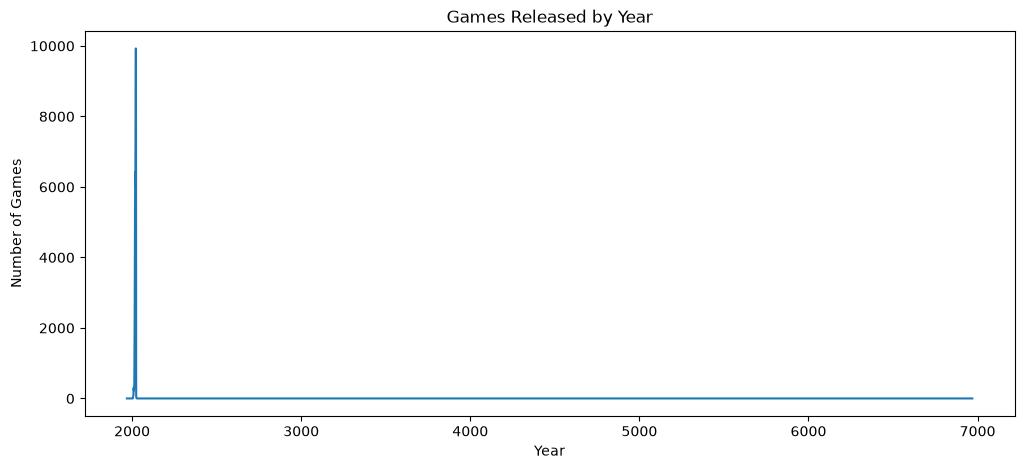

In [57]:
df["release_year"]\
.value_counts()\
.sort_index()\
.plot(
    figsize=(12,5)
)

plt.title("Games Released by Year")
plt.xlabel("Year")
plt.ylabel("Number of Games")
plt.show()

In [24]:
df["release_year"].sort_values().head(20)

64173    1969.0
6365     1997.0
2362     2000.0
2864     2002.0
26744    2003.0
741      2004.0
10110    2006.0
9410     2006.0
34199    2006.0
9198     2006.0
9121     2006.0
3371     2006.0
10336    2006.0
26845    2006.0
3153     2006.0
61111    2006.0
17842    2006.0
24338    2006.0
10465    2006.0
8583     2006.0
Name: release_year, dtype: float64

In [25]:
df["release_year"].value_counts().sort_index().tail(20)

release_year
2016.0    3818
2017.0    5291
2018.0    6431
2019.0    5995
2020.0    7470
2021.0    8895
2022.0    9944
2023.0    7840
2024.0      91
2025.0      14
2026.0       7
2028.0       1
2029.0       2
2030.0       3
2032.0       1
2038.0       1
2069.0       1
2077.0       1
4444.0       1
6969.0       1
Name: count, dtype: int64

In [26]:
df[
    df["Release Date"].str.contains(
        "Coming",
        na=False
    )
]

,Title,Original Price,Discounted Price,Release Date,Link,Game Description,Recent Reviews Summary,All Reviews Summary,Recent Reviews Number,All Reviews Number,Developer,Publisher,Supported Languages,Popular Tags,Game Features,Minimum Requirements,original_price,discounted_price,release_date,release_year
36619,PEAK.53,Free,Free,Coming soon,https://store.steampowered.com/app/2272630/PEA...,PEAK.53 is a tactical shooter developed by Dir...,NaN,NaN,NaN,NaN,"Dirty Bird Games, LLC",FOUR,['English'],"['Early Access', 'PvP', 'Multiplayer', 'Shoote...","['Online PvP', 'Online Co-op', 'Steam Achievem...",OS: | Windows 7 | Processor: | Intel | Memor...,0.00,0.00,NaT,NaN
38536,Adam,$10.49,$10.49,Coming soon,https://store.steampowered.com/app/2409710/Ada...,Adam is a sci-fi themed game that combines Rog...,NaN,NaN,NaN,NaN,Teta Studio Co.,Teta Studio Co.,"['English', 'Turkish']","['Roguelike', 'First-Person', 'Singleplayer', ...",['Single-player'],Requires a 64-bit processor and operating syst...,10.49,10.49,NaT,NaN
40241,MICROVOLTS: Recharged,Free,Free,Coming soon,https://store.steampowered.com/app/1426440/MIC...,Microvolts Recharged is a quirky lobby-based t...,NaN,NaN,NaN,NaN,Masangsoft,Masangsoft,['English'],"['Third-Person Shooter', 'Arena Shooter', 'Sho...","['Single-player', 'Online PvP', 'Online Co-op'...",OS: | Windows 10 | Processor: | Dual-Core In...,0.00,0.00,NaT,NaN
44331,Bullet Hell Monday: Finale,Free,Free,Coming soon,https://store.steampowered.com/app/2501550/Bul...,"""Bullet Hell Monday: Finale"" is a beginner-fri...",NaN,NaN,NaN,NaN,Masayuki Ito,Masayuki Ito,"['English', 'Japanese']","[""Shoot 'Em Up"", 'Bullet Hell', 'Top-Down Shoo...","['Single-player', 'Steam Achievements', 'Parti...",Requires a 64-bit processor and operating syst...,0.00,0.00,NaT,NaN
46482,STG Football,Free,Free,Coming soon,https://store.steampowered.com/app/2218960/STG...,"Officially licensed by the NFLPA, STG Football...",NaN,NaN,NaN,NaN,SuperTeam Games,SuperTeam Games,['English'],"['Sports', 'Football (American)', 'Casual', 'e...","['Single-player', 'Online PvP', 'Online Co-op'...",Requires a 64-bit processor and operating syst...,0.00,0.00,NaT,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71690,Billie Bust Up,Free,Free,Coming soon,https://store.steampowered.com/app/1400830/Bil...,Embark on a thrilling and imaginative odyssey ...,NaN,NaN,NaN,NaN,Giddy Goat Games,Humble Games,"['English', 'French', 'German', 'Japanese', 'P...","['3D Platformer', 'Adventure', 'Cartoony', 'Ex...","['Single-player', 'Shared/Split Screen Co-op',...",Requires a 64-bit processor and operating syst...,0.00,0.00,NaT,NaN
71691,Tempest Rising,Free,Free,Coming soon,https://store.steampowered.com/app/1486920/Tem...,Command one of three distinct factions in a de...,NaN,NaN,NaN,NaN,"Slipgate Ironworks™, 2B Games",THQ Nordic,"['English', 'French', 'Italian', 'German', 'Sp...","['Action', 'Strategy', 'RTS', 'Base Building',...","['Single-player', 'Online PvP', 'Steam Achieve...",Requires a 64-bit processor and operating syst...,0.00,0.00,NaT,NaN
71692,The Walking Dead: Betrayal,Free,Free,Coming soon,https://store.steampowered.com/app/1877320/The...,Betray your friends in this 5-8 person game of...,NaN,NaN,NaN,NaN,Other Ocean Interactive,Skybound Games,"['English', 'French', 'Italian', 'German', 'Sp...","['Early Access', 'Zombies', 'Social Deduction'...","['Online PvP', 'Online Co-op']",OS: | Windows 7 | Processor: | AMD FX-6300 /...,0.00,0.00,NaT,NaN
71697,Winter Memories,Free,Free,Coming soon,https://store.steampowered.com/app/2495450/Win...,After the unforgettable summer memories you’ve...,NaN,NaN,NaN,NaN,Dojin Otome,Kagura Games,"['English', 'Japanese', 'Simplified Chinese']","['Casual', 'RPG', 'Simulation', 'Sexual Conten...",['Single-player'],OS: | Windows® 7/8/8.1/10/11 | Processor: | ...,0.00,0.00,NaT,NaN


11. Review Extraction Functions

In [27]:
def extract_review_percentage(text):

    if pd.isna(text):
        return np.nan

    match = re.search(
        r"(\d+)%",
        str(text)
    )

    if match:
        return int(match.group(1))

    return np.nan

In [28]:
def extract_review_count(text):

    if pd.isna(text):
        return np.nan

    match = re.search(
        r"of the ([\d,]+)",
        str(text)
    )

    if match:
        return int(
            match.group(1)
            .replace(",","")
        )

    return np.nan

12. Review Metrics

In [29]:
df["recent_review_percentage"] = (
    df["Recent Reviews Number"]
    .apply(extract_review_percentage)
)

df["recent_review_count"] = (
    df["Recent Reviews Number"]
    .apply(extract_review_count)
)

df["all_review_percentage"] = (
    df["All Reviews Number"]
    .apply(extract_review_percentage)
)

df["all_review_count"] = (
    df["All Reviews Number"]
    .apply(extract_review_count)
)

13. Review Statistics

In [30]:
df["recent_review_percentage"].describe()

count    37481.000000
mean        76.729436
std         18.005781
min          0.000000
25%         67.000000
50%         81.000000
75%         90.000000
max        100.000000
Name: recent_review_percentage, dtype: float64

In [31]:
df["all_review_percentage"].describe()

count    5371.000000
mean       84.951592
std        11.466325
min        12.000000
25%        80.000000
50%        88.000000
75%        93.000000
max       100.000000
Name: all_review_percentage, dtype: float64

In [32]:
df["all_review_percentage"].value_counts().head(20)

all_review_percentage
95.0    331
94.0    288
93.0    287
96.0    283
97.0    248
92.0    243
89.0    232
90.0    231
91.0    228
88.0    227
87.0    211
85.0    179
86.0    171
83.0    152
84.0    149
80.0    147
98.0    140
81.0    131
82.0    130
79.0    106
Name: count, dtype: int64

In [33]:
df["recent_review_count"].describe()

count     37481.000000
mean        201.664603
std        1771.148316
min          10.000000
25%          19.000000
50%          42.000000
75%         133.000000
max      154266.000000
Name: recent_review_count, dtype: float64

In [34]:
df["all_review_count"].describe()

count    5.371000e+03
mean     1.523301e+04
std      1.209088e+05
min      1.100000e+01
25%      8.810000e+02
50%      2.492000e+03
75%      7.568000e+03
max      7.428921e+06
Name: all_review_count, dtype: float64

14. Missing Review Investigation

In [35]:
df["Recent Reviews Number"].isna().sum()

np.int64(15220)

In [36]:
df["All Reviews Number"].isna().sum()

np.int64(66329)

In [37]:
df[
    df["All Reviews Number"].isna()
].head()

,Title,Original Price,Discounted Price,Release Date,Link,Game Description,Recent Reviews Summary,All Reviews Summary,Recent Reviews Number,All Reviews Number,Developer,Publisher,Supported Languages,Popular Tags,Game Features,Minimum Requirements,original_price,discounted_price,release_date,release_year,recent_review_percentage,recent_review_count,all_review_percentage,all_review_count
6,Remnant II,$34.99,$34.99,"25 Jul, 2023",https://store.steampowered.com/app/1282100/Rem...,Remnant II pits survivors of humanity against ...,Very Positive,NaN,"- 82% of the 19,384 user reviews for this game...",NaN,Gunfire Games,Gearbox Publishing,"['English', 'French', 'Italian', 'German', 'Sp...","['Souls-like', 'Action', 'Adventure', 'RPG', '...","['Single-player', 'Online Co-op', 'Steam Achie...",OS: | Win 10 | Processor: | Intel Core i5-76...,34.99,34.99,2023-07-25,2023.0,82.0,19384.0,NaN,NaN
9,NARAKA: BLADEPOINT,Free,Free,"11 Aug, 2021",https://store.steampowered.com/app/1203220/NAR...,Dive into the legends of the Far East in NARAK...,Mostly Positive,NaN,"- 75% of the 146,529 user reviews for this gam...",NaN,24 Entertainment,NetEase Games Global,"['English', 'Simplified Chinese', 'Traditional...","['Battle Royale', 'Multiplayer', 'Martial Arts...","['Online PvP', 'In-App Purchases', 'Partial Co...",OS: | Windows 7 64-bit or newer | Processor: ...,0.00,0.00,2021-08-11,2021.0,75.0,146529.0,NaN,NaN
29,The Texas Chain Saw Massacre,$18.49,$16.64,"18 Aug, 2023",https://store.steampowered.com/app/1433140/The...,Take on the role of one of the notorious Slaug...,Very Positive,NaN,"- 86% of the 1,834 user reviews for this game ...",NaN,Sumo Digital,Gun Interactive,['English'],"['Horror', 'Survival Horror', 'Gore', 'Team-Ba...","['Online PvP', 'Steam Achievements', 'Full con...",Requires a 64-bit processor and operating syst...,18.49,16.64,2023-08-18,2023.0,86.0,1834.0,NaN,NaN
43,Starfield,$42.99,$42.99,"6 Sep, 2023",https://store.steampowered.com/app/1716740/Sta...,Starfield is the first new universe in 25 year...,NaN,NaN,NaN,NaN,Bethesda Game Studios,Bethesda Softworks,"['English', 'French', 'Italian', 'German', 'Sp...","['Open World', 'Space', 'RPG', 'Singleplayer',...","['Single-player', 'Steam Achievements', 'Full ...",OS: | Windows 10 version 21H1 (10.0.19043) | ...,42.99,42.99,2023-09-06,2023.0,NaN,NaN,NaN,NaN
47,Sengoku Dynasty,$18.99,$18.99,"10 Aug, 2023",https://store.steampowered.com/app/1702010/Sen...,Build and manage villages in an open-world feu...,Mostly Positive,NaN,"- 71% of the 1,345 user reviews for this game ...",NaN,Superkami,Toplitz Productions,"['English', 'French', 'German', 'Spanish - Spa...","['Early Access', 'Adventure', 'Life Sim', 'Sim...","['Single-player', 'Online Co-op', 'Full contro...",OS: | Windows 10 (x64) | Processor: | Intel ...,18.99,18.99,2023-08-10,2023.0,71.0,1345.0,NaN,NaN


In [38]:
print(
    "Recent Review % Missing:",
    df["recent_review_percentage"].isna().sum()
)

print(
    "All Review % Missing:",
    df["all_review_percentage"].isna().sum()
)

Recent Review % Missing: 34219
All Review % Missing: 66329


15. Review Distribution

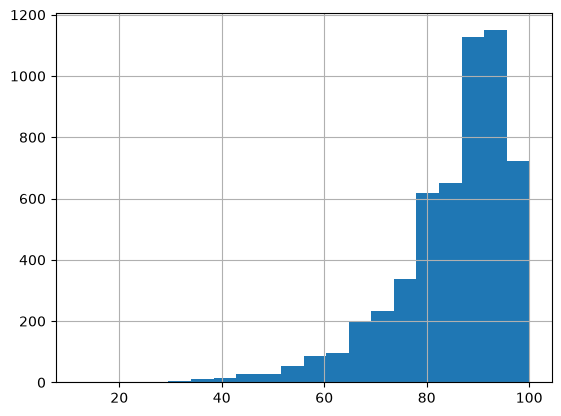

In [39]:
df["all_review_percentage"].hist(
    bins=20
)

plt.show()

16. Developer Analysis

In [40]:
df["Developer"].nunique()

45353

In [41]:
df["Developer"].value_counts().head(20)

Developer
Choice of Games               162
Creobit                       136
Laush Dmitriy Sergeevich      119
Boogygames Studios            106
Sokpop Collective             101
Hosted Games                  100
Reforged Group                 95
Elephant Games                 77
Dnovel                         71
Blender Games                  70
Somer Games                    70
KOEI TECMO GAMES CO., LTD.     63
Ripknot Systems                62
RewindApp                      58
EpiXR Games UG                 55
William at Oxford              55
玫瑰工作室                          54
AMAX Interactive               53
Eipix Entertainment            52
Kairosoft Co.,Ltd              51
Name: count, dtype: int64

In [42]:
df["Developer"].isna().sum()

np.int64(221)

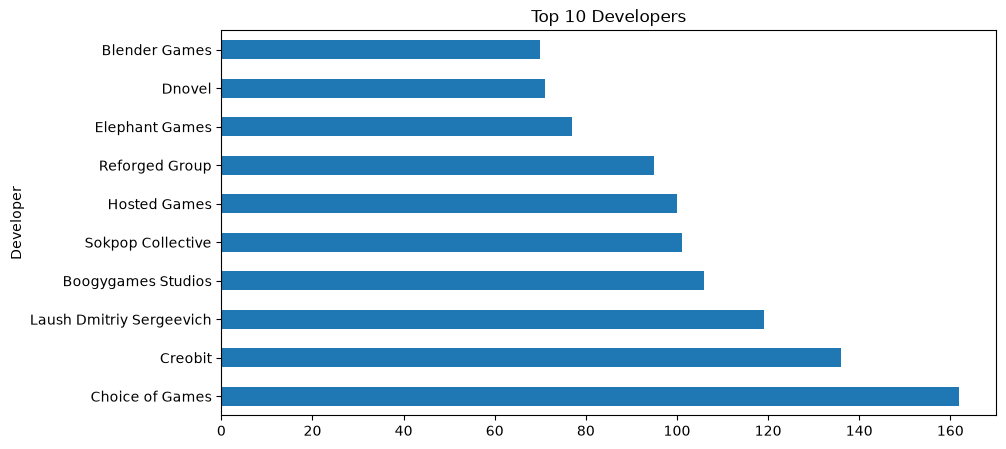

In [59]:
df["Developer"]\
.value_counts()\
.head(10)\
.plot(
    kind="barh",
    figsize=(10,5)
)

plt.title("Top 10 Developers")
plt.show()

17. Publisher Analysis

In [43]:
df["Publisher"].value_counts().head(20)

Publisher
Big Fish Games          459
8floor                  258
Conglomerate 5          199
HH-Games                174
Choice of Games         162
Strategy First          146
THQ Nordic              143
Sekai Project           143
SEGA                    142
Laush Studio            135
Ziggurat                130
Ubisoft                 125
Square Enix             125
Kagura Games            124
Alawar Entertainment    118
Fulqrum Publishing      117
Devolver Digital        116
Plug In Digital         112
Pixel Games UK          111
Slitherine Ltd.         106
Name: count, dtype: int64

In [44]:
df["Publisher"].isna().sum()

np.int64(517)

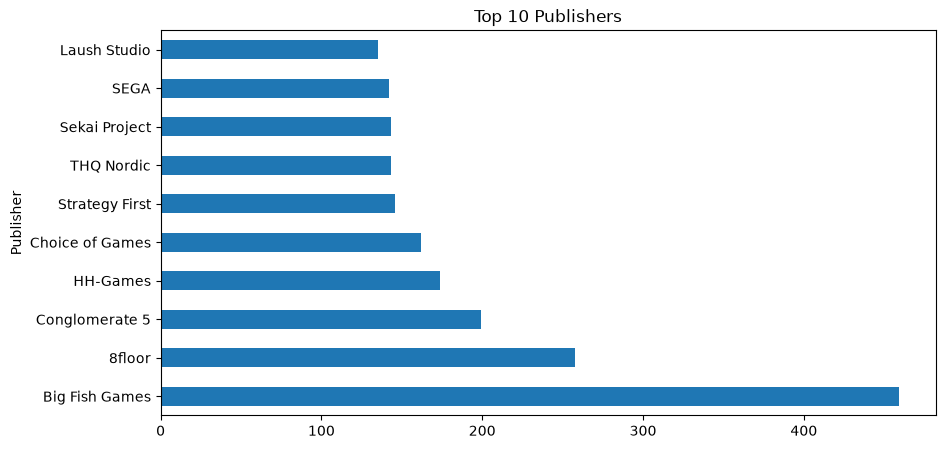

In [58]:
df["Publisher"]\
.value_counts()\
.head(10)\
.plot(
    kind="barh",
    figsize=(10,5)
)

plt.title("Top 10 Publishers")
plt.show()

Duplicate Links

In [45]:
print(df.duplicated().sum())

0


In [56]:
print(
    "Duplicate Steam Links:",
    df["Link"].duplicated().sum()
)

Duplicate Steam Links: 0


18. Count games above $500

In [46]:
len(df[df["original_price"] > 500])

45

19. Count games above $100

In [47]:
len(df[df["original_price"] > 100])

127

20. Top 50 expensive games

In [48]:
df[
    ["Title","original_price","discounted_price"]
].sort_values(
    by="original_price",
    ascending=False
).head(50)

,Title,original_price,discounted_price
52064,Jack-O-Lantern Covers of Darkness,14046333.00,4213899.90
60721,Fright,14046333.00,4213899.90
52065,Roller,14046333.00,4213899.90
39897,Nomad Station,100000.00,100000.00
63158,Orpiment,9999.00,9999.00
13889,BLACKOUT,1999.98,1999.98
47398,Beach Volleyball Competition,1234.57,1234.57
38641,Snowboard,1189.77,39.45
44038,Hidden Water,1101.77,20.42
36878,Hidden Town,1101.77,20.42


Final Checks

In [49]:
df["release_year"].describe()

count    61394.000000
mean      2019.563606
std         22.435048
min       1969.000000
25%       2018.000000
50%       2020.000000
75%       2022.000000
max       6969.000000
Name: release_year, dtype: float64

In [50]:
df[
    df["original_price"] > 500
][
    ["Title","original_price"]
].sort_values(
    by="original_price",
    ascending=False
)

,Title,original_price
52064,Jack-O-Lantern Covers of Darkness,14046333.00
52065,Roller,14046333.00
60721,Fright,14046333.00
39897,Nomad Station,100000.00
63158,Orpiment,9999.00
13889,BLACKOUT,1999.98
47398,Beach Volleyball Competition,1234.57
38641,Snowboard,1189.77
31968,Hidden Islands,1101.77
36878,Hidden Town,1101.77


In [51]:
print(
    "Games Above $500:",
    len(df[df["original_price"] > 500])
)

print(
    "Games Above $1000:",
    len(df[df["original_price"] > 1000])
)

Games Above $500: 45
Games Above $1000: 15


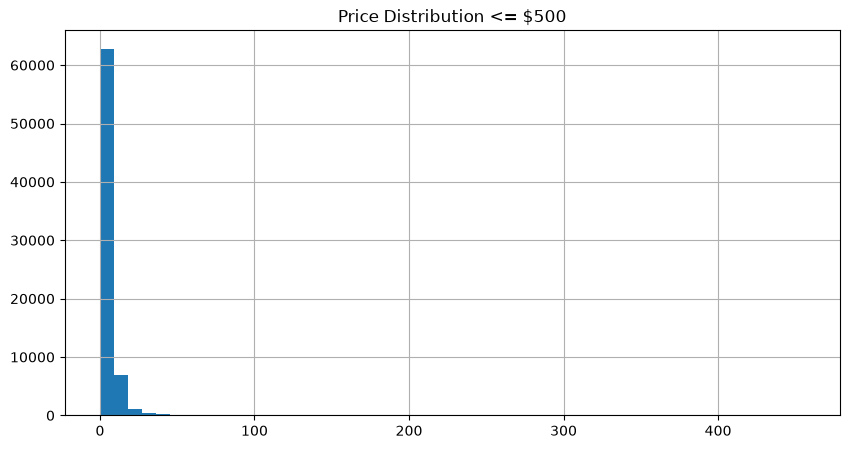

In [52]:
df_filtered = df[
    df["original_price"] <= 500
]

plt.figure(figsize=(10,5))

df_filtered["original_price"].hist(
    bins=50
)

plt.title("Price Distribution <= $500")
plt.show()

In [53]:
print(
    "Recent Review % Available:",
    round(
        df["recent_review_percentage"]
        .notna()
        .mean()*100,
        2
    )
)

print(
    "All Review % Available:",
    round(
        df["all_review_percentage"]
        .notna()
        .mean()*100,
        2
    )
)

Recent Review % Available: 52.27
All Review % Available: 7.49


# EDA Conclusions

## Data Quality Findings

- The dataset contains **71,700 Steam games** across multiple genres, developers, and publishers.
- No significant duplicate records were identified, indicating good overall dataset integrity.
- Review-related fields contain substantial missing values because many games do not have sufficient user reviews to generate Steam review scores.
- Publisher and Developer fields contain less than **1% missing values**, suggesting strong coverage of creator information.
- Release date information is largely complete, with only a small number of missing or unstructured values such as *Coming Soon* and *To Be Announced*.

---

## Price Analysis Findings

- The median game price is significantly lower than the mean price, indicating a highly right-skewed distribution.
- Most Steam games are low-priced, with the majority costing less than **$10**.
- Approximately **99% of games are priced below $30**, while only a very small number of titles exceed this range.
- Several games contain unrealistic prices above **$500**, including extreme values exceeding **$100,000** and **$14 million**.
- These extreme values significantly inflate average price calculations and are considered pricing anomalies rather than representative market prices.

---

## Review Analysis Findings

- Recent review coverage is substantially higher than all-time review coverage.
- Most review scores are concentrated within positive rating ranges, indicating generally favorable player sentiment.
- Missing review values represent unavailable review data rather than negative player feedback.
- Review percentages and review counts provide valuable indicators of player satisfaction and engagement.

---

## Developer and Publisher Findings

- Developer information is available for the vast majority of games.
- Publisher information is also highly complete, with only a small percentage of missing values.
- The dataset includes thousands of unique developers and publishers, highlighting the diversity of the Steam marketplace.

---

## Business Insights

- Steam is dominated by low-priced games, making affordability a key characteristic of the platform.
- A small number of extreme pricing anomalies heavily influence average price metrics and should be treated as outliers during data preparation.
- Publisher and developer information is sufficiently complete for business analysis and reporting.
- Review availability varies considerably across games, suggesting that many titles have limited player engagement or insufficient review activity.
- Player ratings appear to be more useful for measuring game quality and user satisfaction than pricing information alone.

---

## EDA Summary

The exploratory data analysis revealed that the Steam Games dataset is generally clean and suitable for further analysis after handling a small number of pricing anomalies and standardizing date and review-related fields. The platform is characterized by a large number of low-priced games, generally positive player ratings, and comprehensive developer and publisher information. These findings provide a strong foundation for data transformation, SQL analysis, statistical testing, and Power BI dashboard development.

## Data Preparation Recommendations

Based on the EDA findings, the following transformations are recommended:

- Remove unrealistic game prices above $500.
- Standardize release date values and convert invalid dates to null.
- Extract structured review percentages and review counts from text fields.
- Replace missing Publisher and Developer values with "Unknown".
- Retain missing review values as null because they indicate unavailable review data rather than poor ratings.
- Create derived features such as discount amount, discount percentage, and release year for downstream analysis.